In [2]:
import capytaine as cpy
#import autograd.numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import block_diag
import pygmsh
import gmsh
import os
import xarray as xr
import time

## set colorblind-friendly colormap for plots
plt.style.use('tableau-colorblind10')
print(pygmsh.__version__)

7.1.17


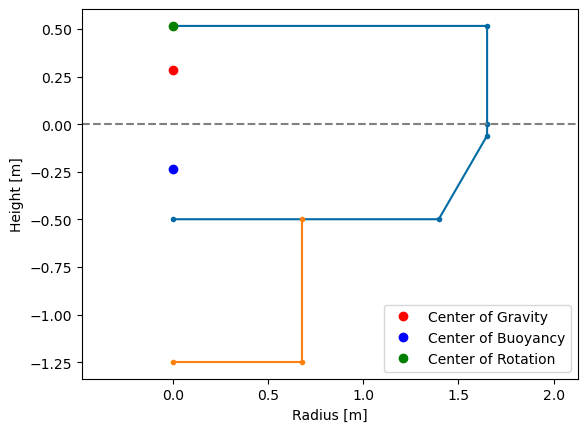

In [3]:
# create mesh
r1 = 3.302/2 # larger/top radius
r2 = 2.794/2 # bottom radius
h1 = 0.5761 # cylinder height
h2 = 0.439 # truncated cone height
box_l = 1.3557 #1.397 # box length
box_w = 1.3557 # box width
box_h =  0.7493 # box height
freeboard = 0.516
mesh_size_factor = 0.4

NSIF_flag = True
offset = -8
NSIF_h1 = 0.50
NSIF_h2 = 0.37
NSIF_h3 = 0.37
NSIF_r1 = 0.88
NSIF_r2 = 0.35


# box subtraction
sub_box_flag = False
sub_box_l = box_l
sub_box_w = box_w - .1
sub_box_h = box_h - .05

cg = [0, 0, .798-freeboard]
cb = [0, 0, .281-freeboard]
cr = [0, 0, freeboard+0] # leaving here, but we'll actually set the center of rotation in WEC-Sim
#cg = [0,0,.242]
#cr = cg

with pygmsh.occ.Geometry() as geom:
    gmsh.option.setNumber('Mesh.MeshSizeFactor', mesh_size_factor)
    cyl = geom.add_cylinder([0, 0, 0],[0, 0, -h1],r1)
    cone = geom.add_cone([0, 0, -h1],[0, 0, -h2],r1,r2)
    box = geom.add_box([0, 0, 0],[box_l,box_w,box_h])

    geom.translate(cyl, [0, 0, freeboard])
    geom.translate(cone, [0, 0, freeboard])
    geom.translate(box, [-box_l/2, -box_w/2, freeboard-h1-h2-box_h])

    if sub_box_flag:
        sub_box1 = geom.add_box([0, 0, 0],[sub_box_l,sub_box_w,sub_box_h])
        sub_box2 = geom.add_box([0.05, 0, -.05],[sub_box_l-.1,sub_box_w,sub_box_h])
        sub_box = geom.boolean_union([sub_box1,sub_box2])
        sub_box = sub_box[0]
        geom.translate(sub_box, [-sub_box_l/2, -sub_box_w/2, freeboard-h1-h2-sub_box_h])
        hollow_box = geom.boolean_difference(box,sub_box)
        geom.boolean_union([hollow_box, cyl, cone])
    else:
        geom.boolean_union([cyl, cone, box])
    
    mesh = geom.generate_mesh() 

if NSIF_flag: 
    with pygmsh.occ.Geometry() as geom:
        gmsh.option.setNumber('Mesh.MeshSizeFactor', mesh_size_factor)
        cyl_NSIF = geom.add_cylinder([0, 0, 0], [0, 0, -NSIF_h1],  NSIF_r1)
        cone1_NSIF   = geom.add_cone([0, 0,  0], [0, 0, NSIF_h2+NSIF_h1], NSIF_r1, NSIF_r2)
        cone2_NSIF   = geom.add_cone([0, 0, -NSIF_h1], [0, 0, -NSIF_h2-NSIF_h1], NSIF_r1, NSIF_r2)
        geom.translate(cone1_NSIF, [0, 0, offset])
        geom.translate(cyl_NSIF, [0, 0, offset])
        geom.translate(cone2_NSIF, [0, 0, offset])
        geom.boolean_union([cone1_NSIF, cyl_NSIF, cone2_NSIF])
        NSIF_mesh = geom.generate_mesh()  

y = [-1*(h1 - freeboard + h2),-1*(h1 - freeboard + h2),-1*(h1 - freeboard),0,freeboard,freeboard]
x = [0,r2,r1,r1,r1,0]
y_box = [-h1-h2+freeboard, -h1-h2-box_h+freeboard, -h1-h2-box_h+freeboard]
x_box = [box_l/2, box_l/2, 0]
plt.plot(x, y,marker='.')
plt.plot(x_box, y_box,marker='.')
plt.plot(cg[0],cg[2],'ro', label='Center of Gravity')
plt.plot(cb[0],cb[2],'bo', label='Center of Buoyancy')
plt.plot(cr[0],cr[2],'go', label='Center of Rotation')
plt.xlim(left=0)
plt.axhline(0, color='grey', linestyle='--')
plt.xlabel('Radius [m]')
plt.ylabel('Height [m]')
plt.axis('equal')
plt.legend()


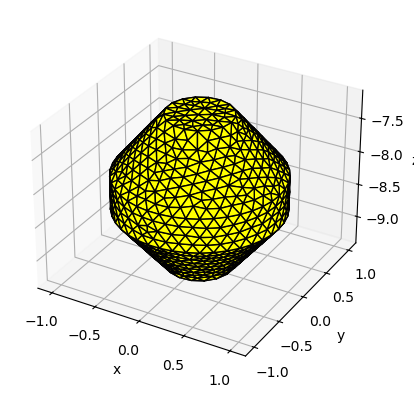

NameError: name 'fig' is not defined

In [6]:
NSIF_fb.show_matplotlib()
fig.savefig('../../paperFigs/NSIFMeshpdf', bbox_inches='tight')

[-1.72667104e-05  1.03671868e-05 -9.84605713e-02]
[-3.80708639e-05 -2.91335729e-06 -4.07100363e-01]


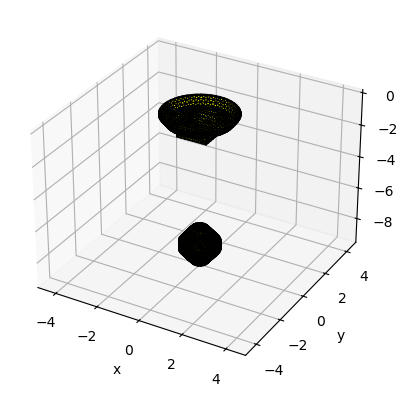

In [4]:
pnr_fb = cpy.FloatingBody.from_meshio(mesh, name="Pioneer")
if NSIF_flag:
    NSIF_fb = cpy.FloatingBody.from_meshio(NSIF_mesh, name="NSIF")



#pnr_fb.show_matplotlib()
#pnr_fb.show()

# calculate pitch moi before cutting
#pnr_fb.add_all_rigid_body_dofs()

#pnr_fb.add_rotation_dof(name='Pitch')

#pnr_fb.mass = 3747
pnr_fb.center_of_mass = cg
pnr_fb.rotation_center = pnr_fb.center_of_mass
print(pnr_fb.center_of_buoyancy)

NSIF_fb.center_of_mass = NSIF_fb.center_of_buoyancy
NSIF_fb.rotation_center = NSIF_fb.center_of_mass

# Capytaine version is >= 2.0
pnr_fb.keep_immersed_part()
pnr_fb.add_all_rigid_body_dofs()

#body_hs = pnr_fb.compute_hydrostatics(rho=1025.0)
#pnr_fb.inertia_matrix[4,4] = 7484

NSIF_fb.keep_immersed_part()
NSIF_fb.add_all_rigid_body_dofs()

print(pnr_fb.center_of_buoyancy)

#both_fb = []
#both_fb.append(pnr_fb)
#both_fb.append(NSIF_fb)
#for i in range(2):
#    both_fb[i].keep_immersed_part()
#    both_fb[i].add_all_rigid_body_dofs()
#both_fb.add_all_rigid_body_dofs()

# combine all bodies to account for B2B interactions
both_fb = pnr_fb + NSIF_fb

both_fb.show_matplotlib()
#both_fb.show()

In [4]:
### Calculate hydrostatics
myBodies = []
myBodies.append(pnr_fb)
myBodies.append(NSIF_fb)

for i in range(2):
    myBodies[i].keep_immersed_part()
    myBodies[i].add_all_rigid_body_dofs()

for i, body in enumerate(myBodies):
    cg = body.center_of_mass
    # Capytaine version is >= 2.0
    body_hs = body.compute_hydrostatics(rho=1023.0)
    vo = body_hs['disp_volume']
    cb = body_hs['center_of_buoyancy']
    khs = body_hs['hydrostatic_stiffness']
    print(vo)
    #print(body_hs['inertia_matrix'])

    # Write hydrostatic stiffness to KH.dat file
    khs_full = np.zeros((6,6))
    khs_full[2:5, 2:5] += khs[2:5, 2:5]

    tmp = 'KH' + '_' + str(i) +'.dat'
    #np.savetxt(tmp, khs_full)

    # Write the other hydrostatics data to Hydrostatics.dat file
    tmp = 'Hydrostatics' + '_' + str(i) + '.dat'
    # f = open(rf'{tmp}','w')
    #f = open(tmp,'w')
    #for j in [0,1,2]:
    #    line =  f'XF = {cb[j]:7.3f} - XG = {cg[j]:7.3f} \n'
    #    print(line)
    #    f.write(line)
    #line = f'Displacement = {vo:E}'
    #f.write(line)
    #f.close()

5.094386348952531
3.396976137895999


In [22]:

start_time = time.time()

ncFName = 'pioneer_NSIF_box.nc'

path,tmp = os.path.split(os.getcwd() + os.path.sep + ncFName)
path += os.path.sep

# combine all bodies to account for B2B interactions

# set frequencies
wCapy =  np.linspace(.1, 10, 100)                  # wave frequencies

headings = np.linspace(0,np.pi/2,1)  

depth = np.infty
density = 1025.0

#print(wCapy)

# call Capytaine solver
print(f'\n-------------------------------\n'
      f'Calling Capytaine BEM solver...\n'
      f'-------------------------------\n'
      f'mesh = {both_fb.name}\n'
      f'w range = {wCapy[0]:.3f} - {wCapy[-1]:.3f} rad/s\n'
      f'dw = {(wCapy[1]-wCapy[0]):.3f} rad/s\n'
      f'no of headings = {len(headings)}\n'
      f'no of radiation & diffraction problems = {len(wCapy)*(len(headings) + len(both_fb.dofs))}\n'
      f'-------------------------------\n')

problems = xr.Dataset(coords={
    'omega': wCapy,
    'wave_direction': headings,
    'radiating_dof': list(both_fb.dofs),
    'water_depth': [depth],
    'rho': [density],
    })

solver = cpy.BEMSolver(green_function=cpy.Delhommeau(
            tabulation_nr=400, tabulation_nz=80,
            tabulation_nb_integration_points=251,
            tabulation_method="legacy"))
capyData = solver.fill_dataset(problems, [both_fb], n_jobs = 2, hydrostatics=True)

# save to .nc file
#cpy.io.xarray.separate_complex_values(capyData).to_netcdf(ncFName, encoding={'radiating_dof': {'dtype': 'U'}, 'influenced_dof': {'dtype': 'U'}})

print('\nCapytaine call complete. Data saved to \n' + ncFName +'\n\n')

print("--- %s seconds ---" % (time.time() - start_time))


-------------------------------
Calling Capytaine BEM solver...
-------------------------------
mesh = Pioneer+NSIF
w range = 0.100 - 10.000 rad/s
dw = 0.100 rad/s
no of headings = 1
no of radiation & diffraction problems = 1300
-------------------------------



[09:50:01] WARNING  Mesh resolution for 390 problems:                                                              
                    The resolution of the mesh might be insufficient for omega ranging from 7.100 to 10.000.       
                    This warning appears when the largest panel of this mesh has radius > wavelength/8.

Output()


Capytaine call complete. Data saved to 
pioneer_NSIF_box.nc


--- 569.8822150230408 seconds ---


In [23]:
def plot_hydrodynamic_coefficients(bem_data,
                                   wave_dir,
                                   ):
    """Plots hydrodynamic coefficients (added mass, radiation damping,
       and wave excitation) based on BEM data.


    Parameters
    ----------
    bem_data
        Linear hydrodynamic coefficients obtained using the boundary
        element method (BEM) code Capytaine, with sign convention
        corrected.
    wave_dir
        Wave direction(s) to plot the
    
    """

    bem_data = bem_data.sel(wave_direction = wave_dir, method='nearest')
    radiating_dofs = bem_data.radiating_dof.values
    radiating_dofs = ['Surge','Heave','Pitch']
    influenced_dofs = bem_data.influenced_dof.values
    influenced_dofs = ['Surge','Heave','Pitch']

    # plots
    fig_am, ax_am = plt.subplots(
        1, 
        len(radiating_dofs),
        tight_layout=True, 
        sharex=True, 
        figsize=(3*len(radiating_dofs), 3),
        squeeze=False
        )
    fig_rd, ax_rd = plt.subplots(
        1,
        len(radiating_dofs),
        tight_layout=True,
        sharex=True, 
        figsize=(3*len(radiating_dofs), 3),
        squeeze=False
        )
    fig_ex, ax_ex = plt.subplots(
        1,
        len(radiating_dofs),
        tight_layout=True, 
        sharex=True, 
        figsize=(3*len(radiating_dofs), 3), 
        squeeze=False
        )
    [ax.grid(True) for axs in (ax_am, ax_rd, ax_ex) for ax in axs.flatten()]
    # plot titles
    fig_am.suptitle('Added Mass Coefficients', fontweight='bold')
    fig_rd.suptitle('Radiation Damping Coefficients', fontweight='bold')
    fig_ex.suptitle('Wave Excitation Coefficients', fontweight='bold')

    sp_idx = 0
    for bod in range(2):
        for i, rdof in enumerate(radiating_dofs):
            if bod == 0:
                rdof = 'Pioneer__' + rdof
            elif bod == 1:
                rdof = 'NSIF__' + rdof
            print(rdof)
            sp_idx += 1
            np.abs(bem_data.diffraction_force.sel(influenced_dof=rdof)).plot(
                ax=ax_ex[0,i], linestyle='dashed', label='Diffraction')
            np.abs(bem_data.Froude_Krylov_force.sel(influenced_dof=rdof)).plot(
                ax=ax_ex[0,i], linestyle='dashdot', label='Froude-Krylov')
            ex_handles, ex_labels = ax_ex[0,i].get_legend_handles_labels()
            ax_ex[0,i].set_title(f'{rdof}')
            ax_ex[0,i].set_xlabel('')
            ax_ex[0,i].set_ylabel('')
            bem_data.added_mass.sel(
                radiating_dof=rdof, influenced_dof=rdof).plot(ax=ax_am[0,i])
            bem_data.radiation_damping.sel(
                radiating_dof=rdof, influenced_dof=rdof).plot(ax=ax_rd[0, i])
            ax_am[0, i].set_xlabel(f'$\omega$', fontsize=10)
            ax_rd[0, i].set_xlabel(f'$\omega$', fontsize=10)
            ax_ex[0, i].set_xlabel(f'$\omega$', fontsize=10)

    fig_ex.legend(ex_handles, ex_labels, loc=(0.08, 0), ncol=2, frameon=False)
    return #[(fig_am,ax_am), (fig_rd,ax_rd), (fig_ex,ax_ex)]

<xarray.DataArray 'radiating_dof' (radiating_dof: 12)>
array(['Pioneer__Surge', 'Pioneer__Sway', 'Pioneer__Heave', 'Pioneer__Roll',
       'Pioneer__Pitch', 'Pioneer__Yaw', 'NSIF__Surge', 'NSIF__Sway',
       'NSIF__Heave', 'NSIF__Roll', 'NSIF__Pitch', 'NSIF__Yaw'], dtype=object)
Coordinates:
    g              float64 9.81
    rho            float64 1.025e+03
    body_name      <U12 'Pioneer+NSIF'
    water_depth    float64 inf
    forward_speed  float64 0.0
  * radiating_dof  (radiating_dof) object 'Pioneer__Surge' ... 'NSIF__Yaw'
Attributes:
    long_name:  Radiating DOF
Pioneer__Surge
Pioneer__Heave
Pioneer__Pitch
NSIF__Surge
NSIF__Heave
NSIF__Pitch


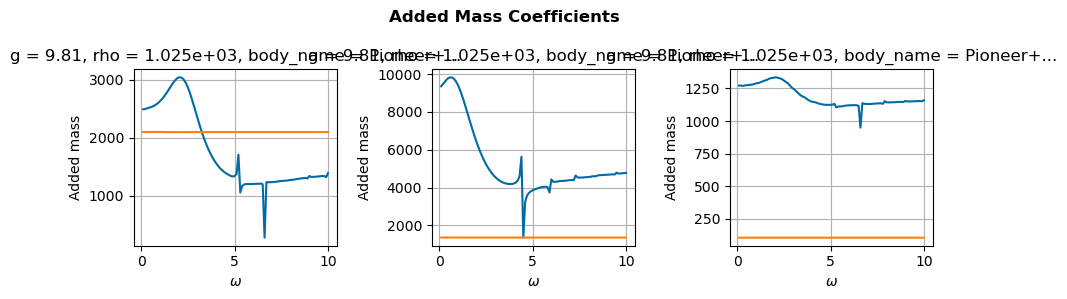

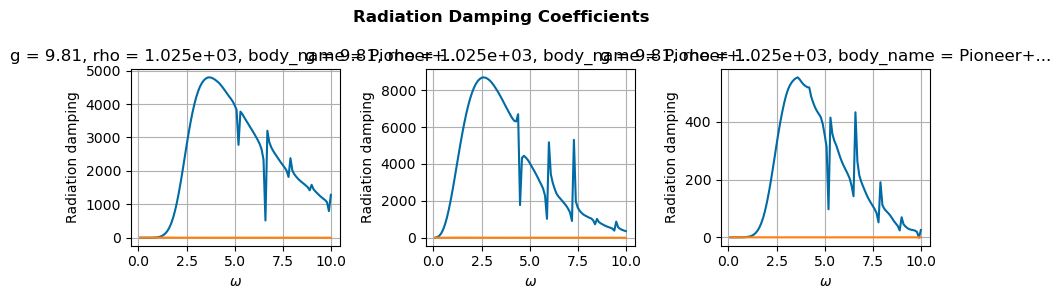

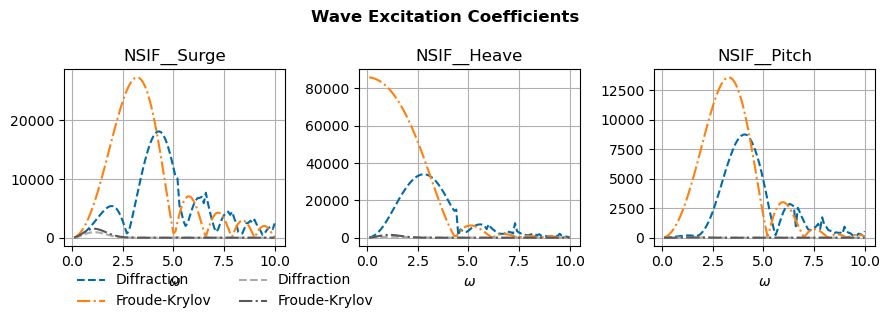

In [24]:
print(capyData['radiating_dof'])
plot_hydrodynamic_coefficients(capyData,headings)

In [25]:
from capytaine.post_pro import impedance
# plot impedance
Zi = impedance(capyData)
#print(Zi)

mag = 20.0 * np.log10(np.abs(Zi))
phase = np.rad2deg(np.unwrap(np.angle(Zi)))
freq = Zi.omega.values/2/np.pi   
fig, axes = plt.subplots(
    2, 
    1,
    tight_layout=True, 
    sharex=True, 
    figsize=(6, 4), 
    squeeze=False
    )

axes[0, 0].semilogx(freq, mag[:, 4, 4])    # Bode magnitude plot
axes[1, 0].semilogx(freq, phase[:, 4, 4])    # Bode phase plot

axes[0, 0].set_ylabel(f'Pitch Impedance \n Mag. (dB)', fontsize=10)
axes[1, 0].set_ylabel(f'Phase. (deg)', fontsize=10)

print(np.argmin(mag[:, 4, 4].values))
print('Natural Freq:')
print(freq[np.argmin(mag[:, 4, 4].values)])

AttributeError: Computing the impedance matrix requires an `inertia_matrix` matrix to be defined in the hydrodynamical dataset